1) a) i). Poisson distribution is reasonable since $Y$ is in the natural numbers.
ii) $\exp$ is our link function beccause the Poisson distribution has a positive rate parameter.

1b) Taking the loss function to be negative log likelihood, we get $-Yf(X) + \exp(f(X)) + \log(Y!)$

1c) $-Y + \exp(f(X))$

1d) For each $j$, take the residual using the equation in 1c), then fit a regression tree on the data with the square loss between the residual to get $h_j$. Then update our tree by taking a negative gradient step scaled by learning rate, which can be estimated at each step greedily using a line search

2a) Suppose we have loss bounded by $0 \leq \mathcal{L} \leq b$. Let $f_\textbf{h}$ be the model with parameters $\textbf{h}$, of which there are $k$ options considered. Let $\mathcal{L}$ be the true expected loss and $\mathcal{\hat{L}}$ be the empirical loss. By the Hoeffding bound, for any $\textbf{h}$, we have 
$$\Pr(\mathcal{L}(f_{\textbf{h}}) \ge \mathcal{\hat{L}} (f_{\textbf{h}}) + t) \leq \exp (\frac{-2l t^2}{b^2})$$

Taking a union bound over $k$ possibilities of $\textbf{h}$, we get that our gap between our estimated risk and true risk for all $k$ possibilities the risk is at most  $ k \exp (\frac{-2l t^2}{b^2})$. Suppose we want a probability of failure at most $\delta$, solving for $t$ we get $t$ is at most 
$$b\sqrt{\frac{\log(2k / \delta)}{2l}}$$

2b) You could be overfitting. Using the same test to select the hyperparameters would mean that your test point are no longer independent of the model, so your estimates of risk might be worse.

In [9]:
import importlib
import problems

importlib.reload(problems)

problems.problem2()

840


100%|███████████████████████████████████████████████████████████████████████████████████████████████| 840/840 [04:00<00:00,  3.50it/s]


best params randforest: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 512}
val best MSE rand forest:  0.3508945380996368
test best  MSE: rand forest 0.3909213442267154


100%|███████████████████████████████████████████████████████████████████████████████████████████████| 544/544 [00:33<00:00, 16.25it/s]


best_params nn: {'n_neighbors': 23, 'p': 3, 'weights': 'distance'}
val best MSE nn: 0.34459077872439103
test best MSE nn: 0.43335578026804183


The empirical risk on the validation set appears to be lower on the validation set than on the test set, and more so for NN than for random forests

In [10]:
import pandas as pd

df = pd.read_csv('dset1-1.csv', header=None)
print(df.head())

     0      1      2      3      4    5
0  0.0  1.558  4.151 -2.741 -0.368 -4.0
1  1.0 -2.179  5.395 -2.018 -4.662  8.0
2  0.0  0.841  3.552 -1.664  3.957 -9.0
3  0.0  0.438  2.388 -0.383 -2.309  3.0
4  1.0 -0.457  2.534 -1.893 -0.634  4.0


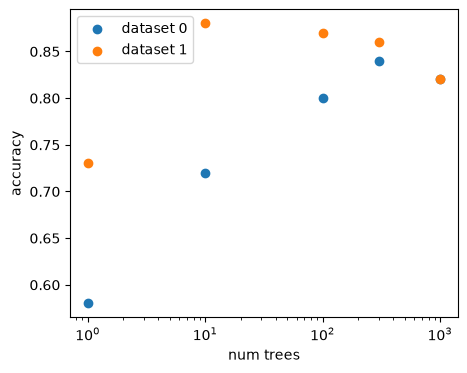

In [12]:
#problem 3
importlib.reload(problems)

problems.problem3()


3a) The accuracy is increasing as the number of trees increases
3b) The accuracy increases then decreases as the trees increases pas 100, perhaps indicating overfitting
3c). The data might have irreducible uncertainty from inferring from these features for dataset 1, so that eventually the model begins to overfit. Dataset 0 might be separable or closer to separable.